# Talhão 62 — Biometric Grid Search with Spatial Matching
**Upgraded Workflow**
1. **Canopy-Peak Alignment:** Bypasses FF3D centroids entirely. We build a CHM from the raw point cloud to find canopy peaks, and geometrically align the theoretical grid to these peaks.
2. **Quality Control (QC):** FF3D segmented trees are aggressively filtered. Any tree that is too short (< 65% of plot max height) or has severe vertical occlusion (> 3m gaps) is discarded.
3. Grid Search over volume/DBH parameters.
4. Evaluation (RMSE per tree) and Extrapolation (m³/ha).



In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "../..")))
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

import os, warnings
import numpy as np
import pandas as pd
import laspy
from tqdm.notebook import tqdm
from concurrent.futures import ProcessPoolExecutor, as_completed
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from scipy.ndimage import maximum_filter
from sklearn.cluster import DBSCAN
from scipy.spatial import cKDTree
from eucalipto.dbh_methods import estimate_dbh
from eucalipto.volume_methods import estimate_volume
warnings.filterwarnings("ignore")


In [2]:
# ══════════════════════════════════════════════════════════
#  CONFIGURATION
# ══════════════════════════════════════════════════════════
RESULT_IFPC_PATH = "/mnt/scratch/dataset/euc/canoa/IFPC-Canoas/Result_IFPC_Canoas.xlsx"
TALHAO_GT        = "062-063"
ALL_PARCELAS     = [500, 503, 508, 509]
NUM_WORKERS      = 8

CLOUD_PATHS = {
    p: f"/mnt/scratch/dataset/euc/canoa/results/ff3d/parcelas_t62/parcela_{p}/classified_cloud.laz"
    for p in ALL_PARCELAS
}



## 1. Helper Functions


In [3]:
def load_field_data(excel_path, talhao, parcelas):
    df_covas = pd.read_excel(excel_path, sheet_name="Covas")
    df_raw = df_covas[
        (df_covas["Talhão"] == talhao) & (df_covas["PAR_CODIGO"].isin(parcelas)) &
        df_covas["Fila"].notnull() & df_covas["Cova"].notnull()
    ].copy()

    df_raw["x_grid"] = df_raw["Cova"].astype(float) * 2.5
    df_raw["y_grid"] = df_raw["Fila"].astype(float) * 3.5

    df_field = df_raw.groupby(["PAR_CODIGO", "Fila", "Cova"]).agg(
        x_grid=("x_grid", "first"), y_grid=("y_grid", "first"),
        dap_cm=("Dap (cm)", "max"), gt_volume=("VTCC Volume (m³)", "sum"), alt_m=("Altura (m)", "max")
    ).reset_index()
    
    df_field["field_id"] = df_field["PAR_CODIGO"].astype(str) + "_" + df_field["Fila"].astype(str) + "_" + df_field["Cova"].astype(str)
    df_field["has_gt_volume"] = df_field["gt_volume"].notnull() & (df_field["gt_volume"] > 0)

    df_extrap = pd.read_excel(excel_path, sheet_name="Parcelas")
    df_extrap = df_extrap[(df_extrap["Talhão"] == talhao) & df_extrap["Parcela"].isin(parcelas)].set_index("Parcela")

    return df_field, df_extrap

def load_lidar_data(cloud_paths):
    points_dict, heights_dict, trunk_masks_dict = {}, {}, {}
    canopy_peaks, qc_trees = {}, {}

    for plot_id, path in cloud_paths.items():
        canopy_peaks[plot_id] = []
        qc_trees[plot_id] = []
        if not os.path.exists(path):
            print(f"  [SKIP] {path}")
            continue

        las = laspy.read(path)
        pts = np.vstack((las.x, las.y, las.z)).T
        fields = list(las.point_format.dimension_names)

        inst = (np.array(las.tree_id) if "tree_id" in fields else np.zeros(len(pts), dtype=np.int32)).copy()
        sem  = (np.array(las.trunk_leaf_label) if "trunk_leaf_label" in fields else np.ones(len(pts), dtype=np.int32))

        # 1. BUILD CHM & FIND CANOPY PEAKS
        z_min = pts[:, 2].min()
        z_norm = pts[:, 2] - z_min
        plot_p90 = np.percentile(z_norm, 90)
        
        res = 0.5
        mask = z_norm > (plot_p90 * 0.4)
        if np.sum(mask) > 0:
            p, zn = pts[mask], z_norm[mask]
            xm, ym = p[:, 0].min(), p[:, 1].min()
            c = ((p[:, 0] - xm) / res).astype(int)
            r = ((p[:, 1] - ym) / res).astype(int)
            df = pd.DataFrame({'r': r, 'c': c, 'z': zn})
            gmax = df.groupby(['r', 'c'])['z'].max().reset_index()
            grid = np.zeros((r.max() + 1, c.max() + 1))
            grid[gmax['r'], gmax['c']] = gmax['z']
            
            lmax = maximum_filter(grid, size=5) == grid
            pr, pc = np.where(lmax & (grid > 0))
            for pr_i, pc_i in zip(pr, pc):
                canopy_peaks[plot_id].append({"x": pc_i * res + xm, "y": pr_i * res + ym})

        # -------------------------------------------------------------
        # ENHANCE EXISTING ISOLATED TREES
        # Reassign unassigned trunk points (tree_id <= 0 & trunk_leaf_label == 1)
        # that physically belong to an already isolated tree's stem cylinder.
        # -------------------------------------------------------------
        known_trunk_mask = (inst > 0) & (sem == 1)
        known_trunk_pts = pts[known_trunk_mask]
        known_trunk_ids = inst[known_trunk_mask]
        
        bg_trunk_mask = (inst <= 0) & (sem == 1)
        bg_trunk_pts = pts[bg_trunk_mask]
        bg_trunk_indices = np.where(bg_trunk_mask)[0]
        
        if len(known_trunk_pts) > 0 and len(bg_trunk_pts) > 0:
            kdt = cKDTree(known_trunk_pts)
            dists, idxs = kdt.query(bg_trunk_pts, distance_upper_bound=0.35)
            valid = dists < 0.35
            for i, is_v in enumerate(valid):
                if is_v:
                    match_pt = known_trunk_pts[idxs[i]]
                    # Proximity along vertical cylinder: dz <= 0.8m, dxy <= 0.30m
                    if abs(bg_trunk_pts[i, 2] - match_pt[2]) <= 0.8:
                        if np.linalg.norm(bg_trunk_pts[i, :2] - match_pt[:2]) <= 0.30:
                            inst[bg_trunk_indices[i]] = known_trunk_ids[idxs[i]]

        # -------------------------------------------------------------
        # 2. EXTRACT AND QC ISOLATED TREES
        # -------------------------------------------------------------
        for tid in np.unique(inst):
            if tid <= 0: continue
            tmask = (inst == tid)
            t_pts = pts[tmask]
            t_sem = sem[tmask]
            if len(t_pts) < 50: continue

            z0, z1 = t_pts[:, 2].min(), t_pts[:, 2].max()
            h = z1 - z0
            
            # QC 1: Tree height >= 55% of plot P90
            if h < (plot_p90 * 0.55): continue
            
            # QC 2: Ground proximity (base within 1.8m of plot minimum elevation)
            if (z0 - z_min) > 1.8: continue

            # QC 3: Trunk presence & vertical span (at least 10m of trunk)
            p_trunk = t_pts[t_sem == 1]
            if len(p_trunk) < 30: continue
            tz0, tz1 = p_trunk[:, 2].min(), p_trunk[:, 2].max()
            trunk_span = tz1 - tz0
            if trunk_span < 10.0: continue

            # QC 4: Trunk vertical continuity (no continuous trunk gaps > 4.0m)
            tbins = np.arange(tz0, tz1 + 1.0, 1.0)
            tcounts, _ = np.histogram(p_trunk[:, 2], bins=tbins)
            tgap_mask = tcounts < 3
            max_tgap, cgap = 0, 0
            for is_g in tgap_mask:
                if is_g: cgap += 1
                else: max_tgap, cgap = max(max_tgap, cgap), 0
            max_tgap = max(max_tgap, cgap)
            if max_tgap > 4.0: continue

            # QC 5: Trunk compactness (reject branch clouds where trunk points spread wider than r90 > 1.45m)
            xy_trunk = p_trunk[:, :2]
            center_trunk = np.median(xy_trunk, axis=0)
            trunk_r90 = np.percentile(np.linalg.norm(xy_trunk - center_trunk, axis=1), 90)
            if trunk_r90 > 1.45: continue

            # Tree passed QC!
            cx, cy = np.median(t_pts[:, 0]), np.median(t_pts[:, 1])
            gid = tid + plot_id * 10000
            heights_dict[gid] = float(h)
            qc_trees[plot_id].append({"global_tid": gid, "tid": int(tid), "x": cx, "y": cy, "h": float(h)})

            t_c = t_pts.copy()
            t_c[:, 0] -= cx; t_c[:, 1] -= cy; t_c[:, 2] -= z0
            points_dict[gid] = t_c
            trunk_masks_dict[gid] = (t_sem == 1)

    return points_dict, heights_dict, trunk_masks_dict, canopy_peaks, qc_trees

def align_and_match(canopy_peaks, qc_trees, plot_df):
    L = np.array([[t["x"], t["y"]] for t in canopy_peaks]) if len(canopy_peaks) > 0 else np.empty((0,2))
    F = plot_df[["x_grid", "y_grid"]].values
    gt_heights = plot_df["alt_m"].values
    
    T_pts = np.array([[t["x"], t["y"]] for t in qc_trees]) if len(qc_trees) > 0 else np.empty((0,2))
    T_h = np.array([t["h"] for t in qc_trees]) if len(qc_trees) > 0 else np.empty((0,))
    
    best_score = -float("inf")
    best_Fr = None
    best_ang = 0
    
    mA = T_pts.mean(axis=0) if len(T_pts) >= 3 else L.mean(axis=0)
    
    for swap in [False, True]:
        F_curr = F[:, [1,0]] if swap else F
        mB = F_curr.mean(axis=0)
        Bc = F_curr - mB
        
        for deg in range(0, 360, 2):
            t = np.radians(deg); c, s = np.cos(t), np.sin(t)
            R = np.array([[c, -s],[s, c]])
            Br = Bc @ R.T
            
            for dx in np.linspace(-4, 4, 17):
                for dy in np.linspace(-4, 4, 17):
                    Fr_candidate = Br + mA + np.array([dx, dy])
                    
                    if len(T_pts) >= 3:
                        D = cdist(T_pts, Fr_candidate)
                        min_d = np.min(D, axis=1)
                        if np.max(min_d) > 1.5: continue
                        closest = np.argmin(D, axis=1)
                        if len(set(closest)) < min(len(qc_trees), 10): continue
                        
                        score = 0.0
                        for ti, si in enumerate(closest):
                            d = min_d[ti]
                            score += (2.0 - d)
                            if plot_df.iloc[si]["has_gt_volume"]:
                                score += 4.0
                                if not np.isnan(gt_heights[si]):
                                    h_diff = abs(T_h[ti] - gt_heights[si])
                                    score -= min(4.0, 0.4 * h_diff)
                    else:
                        D = cdist(L, Fr_candidate)
                        ri, ci = linear_sum_assignment(D)
                        score = -D[ri, ci].sum()
                        
                    if score > best_score:
                        best_score = score
                        best_Fr = Fr_candidate
                        best_ang = deg

    # Match QC trees to best_Fr using linear sum assignment
    matches = []
    if len(qc_trees) > 0 and best_Fr is not None:
        D = cdist(best_Fr, T_pts)
        ri, ci = linear_sum_assignment(D)
        for f_idx, t_idx in zip(ri, ci):
            dist = D[f_idx, t_idx]
            if dist < 1.5: # within 1.5m of theoretical spot
                row = plot_df.iloc[f_idx]
                matches.append({
                    "global_tid": qc_trees[t_idx]["global_tid"],
                    "tid": qc_trees[t_idx]["tid"],
                    "field_id": row["field_id"],
                    "has_gt_volume": row["has_gt_volume"],
                    "gt_volume": row["gt_volume"] if row["has_gt_volume"] else np.nan,
                    "gt_dbh": row["dap_cm"] if row["has_gt_volume"] else np.nan,
                    "gt_height": row["alt_m"] if row["has_gt_volume"] else np.nan,
                    "plot_id": row["PAR_CODIGO"],
                    "dist": dist
                })
    return L, best_Fr, T_pts if len(qc_trees)>0 else np.empty((0,2)), best_ang, best_score, matches

# ──────────────────────────────────────────────────────────
# Grid-search worker
# ──────────────────────────────────────────────────────────
def _init(pts, ht, tm):
    global _P, _H, _T
    _P, _H, _T = pts, ht, tm

def _run(args):
    tid, dm, dp, vm, vp = args
    pts, h, tmask = _P[tid], _H[tid], _T[tid]
    trunk = pts[tmask] if tmask.sum() > 10 else pts

    try: dbh, _ = estimate_dbh(trunk, method=dm, **dict(dp))
    except Exception: dbh = float("nan")

    try:
        if vm == "cylinder":
            if np.isnan(dbh): raise ValueError("NaN DBH")
            r = estimate_volume(trunk, dbh_cm=dbh, height_m=h, method="cylinder")
        elif vm in ("axis_profile", "frustum", "taper"):
            r = estimate_volume(trunk, method=vm, **dict(vp))
        else:
            r = estimate_volume(trunk, method=vm, **dict(vp))
        vol = r["volume_m3"]
    except Exception: vol = float("nan")

    return {"global_tid": tid, "dbh_method": dm, "dbh_params": str(dict(dp)),
            "volume_method": vm, "volume_params": str(dict(vp)),
            "dbh_cm": dbh, "volume_m3": vol, "height_m": h}







## 2. Load Data, Filter & Match


Loading field data…
Loading LiDAR clouds & Generating CHM Peaks…
Parcela 500: 33 Canopy peaks | 5 QC-passed trees → 5 pairs (5 valid with GT: [20, 26, 36, 39, 29])
Parcela 503: 31 Canopy peaks | 10 QC-passed trees → 10 pairs (8 valid with GT: [34, 26, 22, 32, 13, 7, 1, 36])
Parcela 508: 35 Canopy peaks | 20 QC-passed trees → 20 pairs (16 valid with GT: [27, 25, 13, 18, 15, 26, 20, 9, 30, 39, 2, 16, 31, 23, 34, 22])
Parcela 509: 23 Canopy peaks | 16 QC-passed trees → 14 pairs (8 valid with GT: [27, 18, 20, 25, 6, 4, 1, 7])


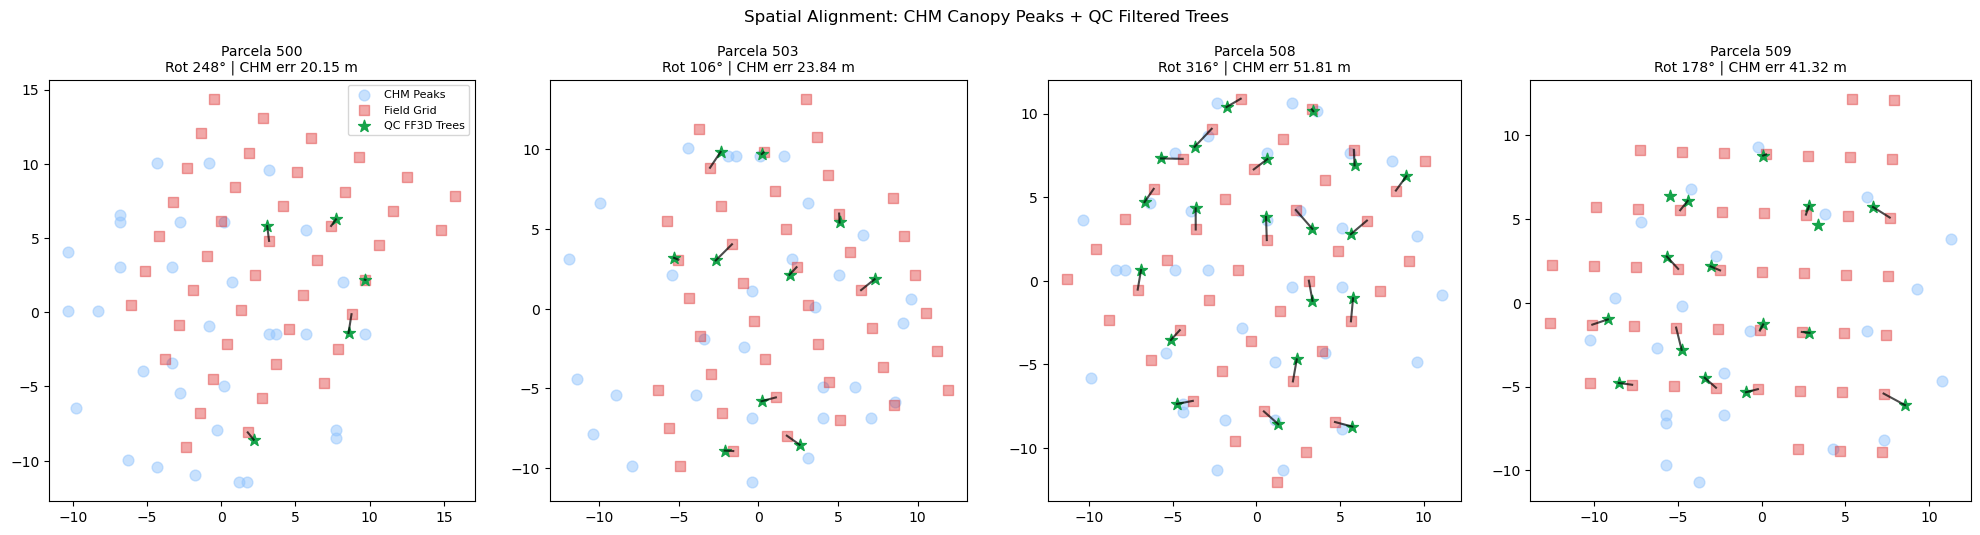


Total matched pairs: 49  |  with GT volume: 37


In [4]:
print("Loading field data…")
df_field, df_extrap = load_field_data(RESULT_IFPC_PATH, TALHAO_GT, ALL_PARCELAS)

print("Loading LiDAR clouds & Generating CHM Peaks…")
points_dict, heights_dict, trunk_masks_dict, canopy_peaks, qc_trees = load_lidar_data(CLOUD_PATHS)

all_matches = []
n_plots = sum(1 for p in ALL_PARCELAS if canopy_peaks.get(p))

fig, axes = plt.subplots(1, n_plots, figsize=(5 * n_plots, 5))
if n_plots == 1: axes = [axes]
ax_iter = iter(axes)

for plot_id in ALL_PARCELAS:
    c_peaks = canopy_peaks.get(plot_id, [])
    if not c_peaks: continue

    plot_df = df_field[df_field["PAR_CODIGO"] == plot_id].reset_index(drop=True)
    L, Fr, T_pts, angle, mean_err, matches = align_and_match(c_peaks, qc_trees.get(plot_id, []), plot_df)
    all_matches.extend(matches)

    valid_gt_tids = [m.get("tid", m["global_tid"] % 10000) for m in matches if m["has_gt_volume"]]
    n_with_gt = len(valid_gt_tids)
    print(f"Parcela {plot_id}: {len(L)} Canopy peaks | {len(qc_trees.get(plot_id, []))} QC-passed trees "
          f"→ {len(matches)} pairs ({n_with_gt} valid with GT: {valid_gt_tids})")

    ax = next(ax_iter)
    ax.scatter(L[:, 0], L[:, 1], c="#93c5fd", s=60, alpha=0.5, label="CHM Peaks")
    ax.scatter(Fr[:, 0], Fr[:, 1], c="#dc2626", s=50, marker="s", alpha=0.4, label="Field Grid")
    if len(T_pts) > 0:
        ax.scatter(T_pts[:, 0], T_pts[:, 1], c="#16a34a", s=80, marker="*", label="QC FF3D Trees")
        # Draw match lines
        matched_tids = [m["global_tid"] for m in matches]
        matched_fids = [m["field_id"] for m in matches]
        
        for m in matches:
            t_idx = next(i for i, t in enumerate(qc_trees[plot_id]) if t["global_tid"] == m["global_tid"])
            f_idx = plot_df.index[plot_df["field_id"] == m["field_id"]].tolist()[0]
            ax.plot([T_pts[t_idx, 0], Fr[f_idx, 0]], [T_pts[t_idx, 1], Fr[f_idx, 1]], "k-", alpha=0.7, lw=1.5)

    ax.set_title(f"Parcela {plot_id}\nRot {angle}° | CHM err {mean_err:.2f} m", fontsize=10)
    ax.set_aspect("equal")
    if ax == axes[0]: ax.legend(fontsize=8)

plt.suptitle("Spatial Alignment: CHM Canopy Peaks + QC Filtered Trees", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

match_df = pd.DataFrame(all_matches)
print(f"\nTotal matched pairs: {len(match_df)}  |  with GT volume: {match_df['has_gt_volume'].sum()}")




### 2.1 Export Recovered Point Clouds for Visual Inspection
Save the point cloud with updated `tree_id` labels (after Strategies A & B trunk recovery) so you can compare before vs after in CloudCompare.

In [5]:
import os
import laspy
import numpy as np
from scipy.spatial import cKDTree

EXPORT_DIR = "/home/matheuspimenta/euc/projeto_eucalipto/results/canoa/parcelas_t62/recovered_clouds"
os.makedirs(EXPORT_DIR, exist_ok=True)

for plot_id, in_path in CLOUD_PATHS.items():
    if not os.path.exists(in_path):
        continue
        
    las = laspy.read(in_path)
    pts = np.vstack((las.x, las.y, las.z)).T
    fields = list(las.point_format.dimension_names)
    inst = (np.array(las.tree_id) if "tree_id" in fields else np.zeros(len(pts), dtype=np.int32)).copy()
    sem = (np.array(las.trunk_leaf_label) if "trunk_leaf_label" in fields else np.ones(len(pts), dtype=np.int32))
    
    # Enhance existing isolated trees by reassigning unassigned trunk points within 30cm of the stem cylinder
    known_trunk_mask = (inst > 0) & (sem == 1)
    known_trunk_pts = pts[known_trunk_mask]
    known_trunk_ids = inst[known_trunk_mask]
    
    bg_trunk_mask = (inst <= 0) & (sem == 1)
    bg_trunk_pts = pts[bg_trunk_mask]
    bg_trunk_indices = np.where(bg_trunk_mask)[0]
    
    reassigned = 0
    if len(known_trunk_pts) > 0 and len(bg_trunk_pts) > 0:
        kdt = cKDTree(known_trunk_pts)
        dists, idxs = kdt.query(bg_trunk_pts, distance_upper_bound=0.35)
        valid = dists < 0.35
        for i, is_v in enumerate(valid):
            if is_v:
                match_pt = known_trunk_pts[idxs[i]]
                if abs(bg_trunk_pts[i, 2] - match_pt[2]) <= 0.8:
                    if np.linalg.norm(bg_trunk_pts[i, :2] - match_pt[:2]) <= 0.30:
                        inst[bg_trunk_indices[i]] = known_trunk_ids[idxs[i]]
                        reassigned += 1

    out_path = os.path.join(EXPORT_DIR, f"parcela_{plot_id}_recovered.laz")
    out_las = laspy.LasData(las.header)
    out_las.points = las.points.copy()
    out_las.tree_id = inst
    out_las.write(out_path)
    print(f"Saved: {out_path} (Reassigned {reassigned} trunk points to existing treeIDs)")



Saved: /home/matheuspimenta/euc/projeto_eucalipto/results/canoa/parcelas_t62/recovered_clouds/parcela_500_recovered.laz (Reassigned 300 trunk points to existing treeIDs)
Saved: /home/matheuspimenta/euc/projeto_eucalipto/results/canoa/parcelas_t62/recovered_clouds/parcela_503_recovered.laz (Reassigned 246 trunk points to existing treeIDs)
Saved: /home/matheuspimenta/euc/projeto_eucalipto/results/canoa/parcelas_t62/recovered_clouds/parcela_508_recovered.laz (Reassigned 461 trunk points to existing treeIDs)
Saved: /home/matheuspimenta/euc/projeto_eucalipto/results/canoa/parcelas_t62/recovered_clouds/parcela_509_recovered.laz (Reassigned 605 trunk points to existing treeIDs)


## 3. Select Plot(s) to Analyse


In [6]:
SELECTED_PARCELAS = [500, 503, 508, 509]

sel_match_df = match_df[match_df["plot_id"].isin(SELECTED_PARCELAS) & match_df["has_gt_volume"]]
match_dict = sel_match_df.set_index("global_tid").to_dict(orient="index")
matched_tids = list(match_dict.keys())

print(f"Selected parcelas: {SELECTED_PARCELAS}")
print(f"High-Quality Trees to evaluate: {len(matched_tids)}")
print(f"GT volume sum: {sel_match_df['gt_volume'].sum():.3f} m³")



Selected parcelas: [500, 503, 508, 509]
High-Quality Trees to evaluate: 37
GT volume sum: 11.209 m³


## 4. Preliminary Probe


In [7]:
DEFAULT_DBH_PARAMS = dict(offset_range=0.3, n_slices=7, slice_thickness=0.16, ransac_thresh=0.02)
PROBE_CONFIGS = [
    ("cylinder",     dict()),
    ("voxel",        dict(voxel_size=0.08)),
    ("axis_profile", dict(n_slices=20, slice_thickness=0.20, radius_percentile=20.0, min_points_per_slice=5)),
    ("frustum",      dict(n_height_samples=15, slice_thickness=0.20, ransac_thresh=0.05, min_inliers=3)),
    ("taper",        dict(n_height_samples=15, slice_thickness=0.20, ransac_thresh=0.05, min_inliers=3)),
]

probe_rows = []
for tid in matched_tids:
    pts, h, tmask = points_dict[tid], heights_dict[tid], trunk_masks_dict[tid]
    trunk = pts[tmask] if tmask.sum() > 10 else pts
    try: dbh, _ = estimate_dbh(trunk, method="ensemble", **DEFAULT_DBH_PARAMS)
    except Exception: dbh = float("nan")

    for vm, vp in PROBE_CONFIGS:
        try:
            if vm == "cylinder":
                if np.isnan(dbh): raise ValueError("NaN DBH")
                r = estimate_volume(trunk, dbh_cm=dbh, height_m=h, method="cylinder")
            else: r = estimate_volume(trunk, method=vm, **vp)
            vol = r["volume_m3"]
        except Exception: vol = float("nan")
        probe_rows.append({"global_tid": tid, "method": vm, "volume_m3": vol, "dbh_cm": dbh, "height_m": h, "gt_volume": match_dict[tid]["gt_volume"]})

df_probe = pd.DataFrame(probe_rows)
total_gt = sel_match_df["gt_volume"].sum()
print(f"{'Method':<14} {'Est. Total':>12} {'Rel Err':>9} {'RMSE':>8}")
print("-" * 48)
for vm, grp in df_probe.groupby("method"):
    vg = grp.dropna(subset=["volume_m3", "gt_volume"])
    if len(vg) == 0: continue
    est = vg["volume_m3"].sum()
    rel = (est - total_gt) / total_gt * 100
    rmse = np.sqrt(((vg["volume_m3"] - vg["gt_volume"])**2).mean())
    print(f"{vm:<14} {est:>12.3f}  {rel:>+8.1f}%  {rmse:>7.4f}")



Method           Est. Total   Rel Err     RMSE
------------------------------------------------
axis_profile         31.531    +181.3%   1.1579
cylinder            192.723   +1619.4%  11.8899
frustum             222.056   +1881.1%   9.4786
taper              5094.212  +45349.1%  567.4805
voxel                11.520      +2.8%   0.2078


## 5. Full Parallel Grid Search


In [8]:
dbh_grids = {
    "ensemble":     [{"offset_range": o, "n_slices": n, "slice_thickness": st, "ransac_thresh": rt}
                     for o in [0.2, 0.3, 0.4] for n in [5, 7, 10] for st in [0.10, 0.16, 0.20] for rt in [0.01, 0.02, 0.03]],
    "single_ransac":[{"slice_thickness": st, "ransac_thresh": rt} for st in [0.10, 0.16, 0.20] for rt in [0.01, 0.02, 0.03]],
    "ls":           [{"slice_thickness": st} for st in [0.10, 0.16, 0.20]],
}
volume_grids = {
    "cylinder":     [{}],
    "voxel":        [{"voxel_size": vs} for vs in [0.05, 0.07, 0.08, 0.10, 0.12]],
    "axis_profile": [{"n_slices": ns, "slice_thickness": st, "radius_percentile": rp, "min_points_per_slice": mp}
                     for ns in [10, 15, 20, 30] for st in [0.15, 0.20, 0.30]
                     for rp in [15.0, 20.0, 25.0, 30.0] for mp in [5, 10]],
    "frustum":      [{"n_height_samples": nh, "slice_thickness": st, "ransac_thresh": rt, "min_inliers": 3}
                     for nh in [10, 15, 20] for st in [0.15, 0.20, 0.30] for rt in [0.04, 0.06, 0.08, 0.10]],
    "taper":        [{"n_height_samples": nh, "slice_thickness": st, "ransac_thresh": rt, "min_inliers": 3}
                     for nh in [10, 15, 20] for st in [0.15, 0.20, 0.30] for rt in [0.04, 0.06, 0.08, 0.10]],
}

DEF_DBH, DEF_DBH_P = "ensemble", tuple(sorted(DEFAULT_DBH_PARAMS.items()))
tasks = []
for dm, grids in dbh_grids.items():
    for g in grids:
        for tid in matched_tids: tasks.append((tid, dm, tuple(sorted(g.items())), "cylinder", ()))
for vm, grids in volume_grids.items():
    if vm == "cylinder": continue
    for g in grids:
        for tid in matched_tids: tasks.append((tid, DEF_DBH, DEF_DBH_P, vm, tuple(sorted(g.items()))))

results = []
with ProcessPoolExecutor(max_workers=NUM_WORKERS, initializer=_init, initargs=(points_dict, heights_dict, trunk_masks_dict)) as exe:
    futs = [exe.submit(_run, t) for t in tasks]
    for fut in tqdm(as_completed(futs), total=len(futs), desc="Grid Search"): results.append(fut.result())

df_res = pd.DataFrame(results)
df_res["gt_volume"] = df_res["global_tid"].map(lambda t: match_dict[t]["gt_volume"])
df_res["gt_dbh"]    = df_res["global_tid"].map(lambda t: match_dict[t]["gt_dbh"])
df_res["plot_id"]   = df_res["global_tid"].map(lambda t: match_dict[t]["plot_id"])



Grid Search:   0%|          | 0/9842 [00:00<?, ?it/s]

## 6. Evaluate — Volume


In [9]:
rows = []
for (dm, dp, vm, vp), grp in df_res.groupby(["dbh_method","dbh_params","volume_method","volume_params"]):
    vg = grp.dropna(subset=["volume_m3", "gt_volume"])
    if len(vg) < 3: continue
    est = vg["volume_m3"].sum()
    rel = (est - total_gt) / total_gt * 100
    rmse = np.sqrt(((vg["volume_m3"] - vg["gt_volume"])**2).mean())
    mae = (vg["volume_m3"] - vg["gt_volume"]).abs().mean()
    corr = vg["volume_m3"].corr(vg["gt_volume"])
    rows.append({"dbh_method": dm, "volume_method": vm, "dbh_params": dp, "volume_params": vp, "n_trees": len(vg), "est_total_m3": est, "plot_rel_err_pct": rel, "abs_plot_err": abs(rel), "rmse_m3": rmse, "mae_m3": mae, "corr": corr})

df_eval = pd.DataFrame(rows).sort_values("rmse_m3")
best_per_method_rmse = []
for vm in df_eval["volume_method"].unique(): best_per_method_rmse.append(df_eval[df_eval["volume_method"] == vm].iloc[0])
df_best_rmse = pd.DataFrame(best_per_method_rmse).sort_values("rmse_m3")

def _get_sub(conf, df):
    vm, dm = conf["volume_method"], conf["dbh_method"]
    if vm == "cylinder": return df[(df["volume_method"] == vm) & (df["dbh_method"] == dm) & (df["dbh_params"] == conf["dbh_params"])]
    return df[(df["volume_method"] == vm) & (df["volume_params"] == conf["volume_params"])]


### 6.1 Per-Tree Scatter — Fixed Best Config per Method


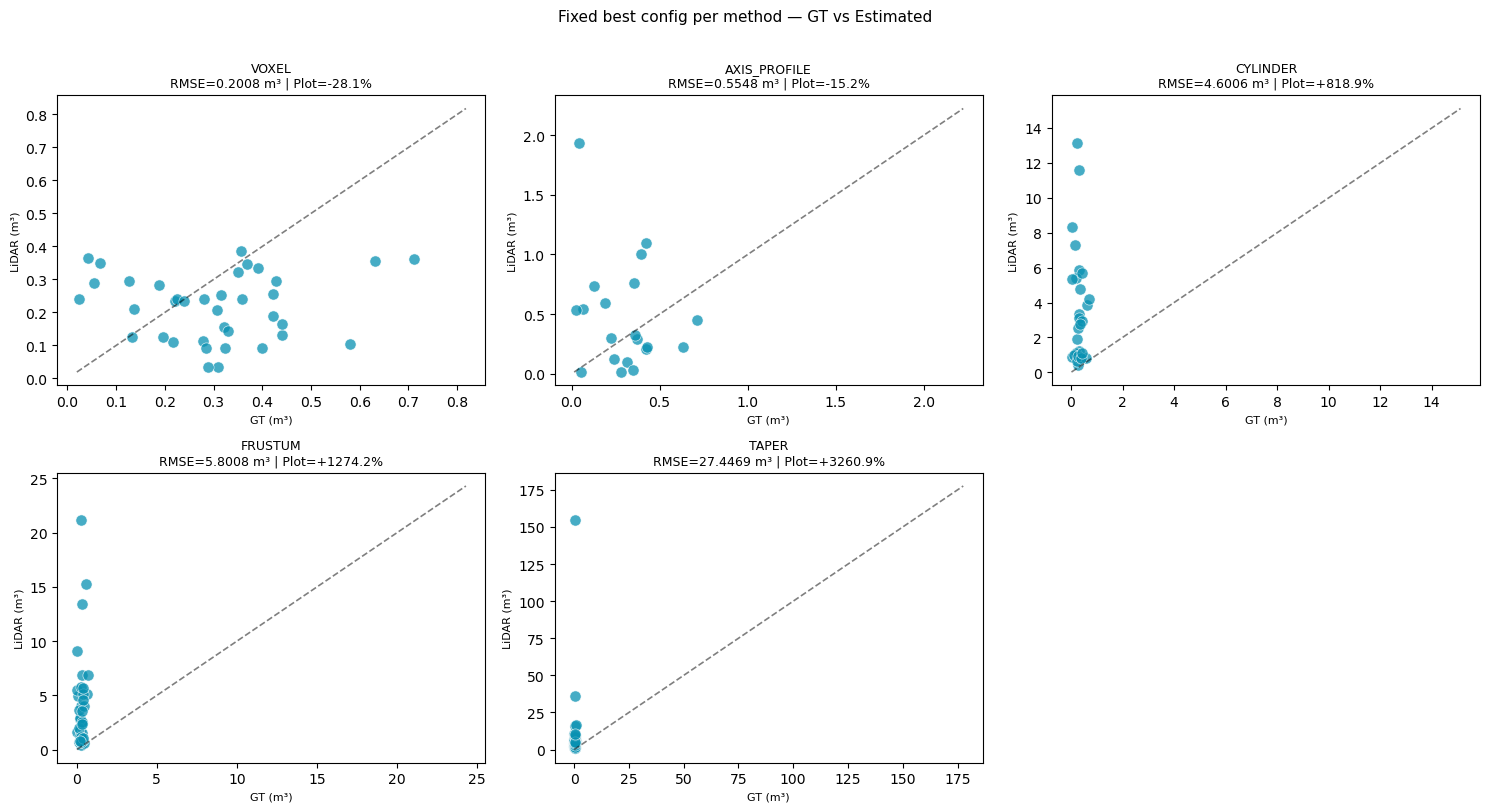

In [10]:
fig, axes = plt.subplots(int(np.ceil(len(df_best_rmse)/3)), 3, figsize=(15, 4 * int(np.ceil(len(df_best_rmse)/3))))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]
for ax, (_, conf) in zip(axes_flat, df_best_rmse.iterrows()):
    sub = _get_sub(conf, df_res).dropna(subset=["volume_m3", "gt_volume"])
    ax.scatter(sub["gt_volume"], sub["volume_m3"], c="#0891b2", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)
    all_vals = pd.concat([sub["gt_volume"], sub["volume_m3"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)
    ax.set_title(f"{conf['volume_method'].upper()}\nRMSE={conf['rmse_m3']:.4f} m³ | Plot={conf['plot_rel_err_pct']:+.1f}%", fontsize=9)
    ax.set_xlabel("GT (m³)", fontsize=8); ax.set_ylabel("LiDAR (m³)", fontsize=8)
for ax in axes_flat[len(df_best_rmse):]: ax.set_visible(False)
plt.suptitle("Fixed best config per method — GT vs Estimated", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


### 6.2 Oracle Analysis — Best Config Chosen Per Individual Tree


╔══ ORACLE vs FIXED CONFIG — Volume RMSE per method ══╗
Method           Oracle RMSE   Fixed RMSE      Gap
----------------------------------------------------
  voxel              0.0739        0.2008   +0.1270
  axis_profile       0.1588        0.5548   +0.3960
  cylinder           1.0669        4.6006   +3.5337
  frustum            1.1182        5.8008   +4.6826
  taper              1.5864       27.4469  +25.8605


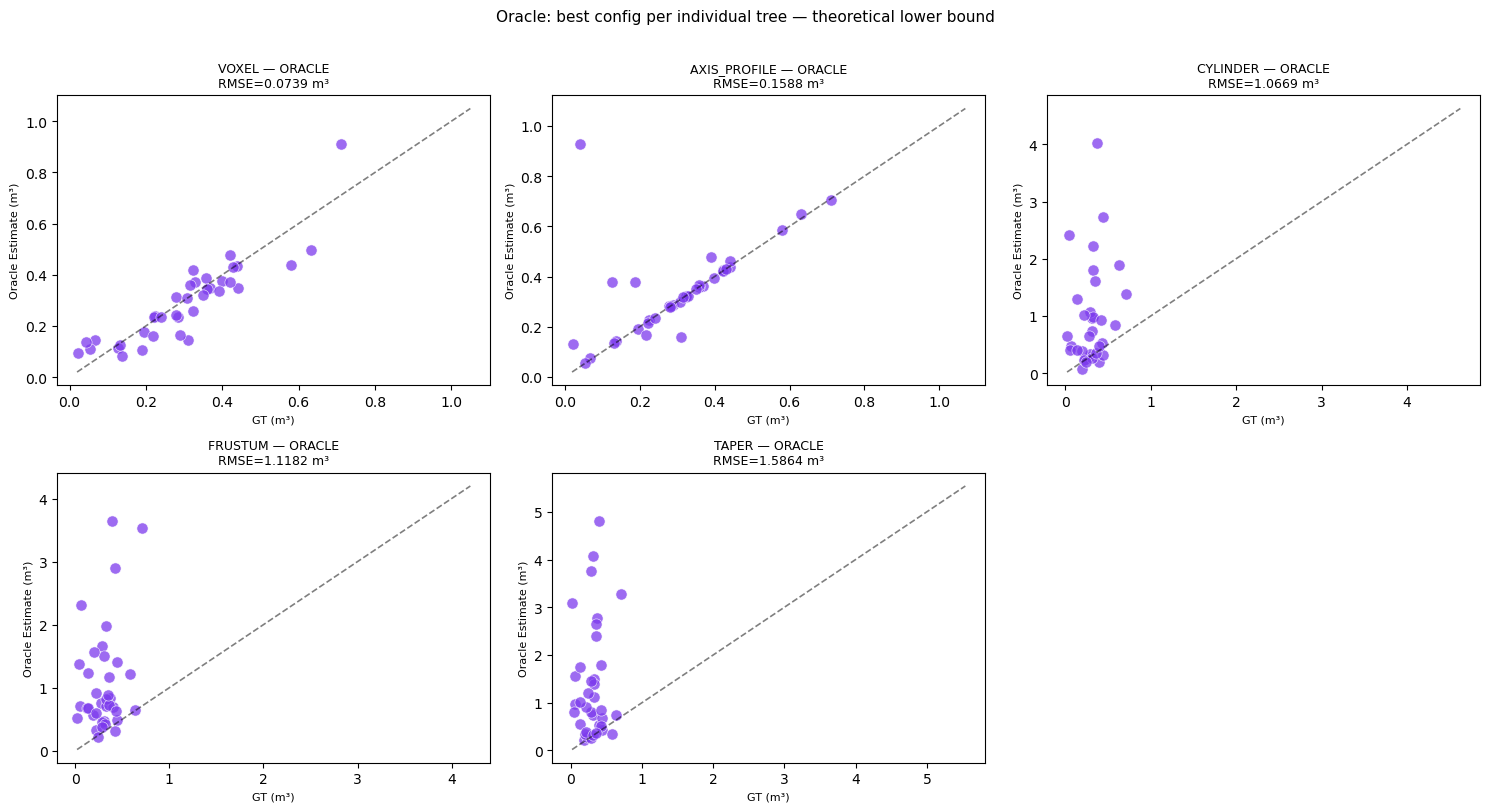

In [11]:
oracle_rows = []
for vm in df_eval["volume_method"].unique():
    vm_data = df_res[df_res["volume_method"] == vm].dropna(subset=["volume_m3", "gt_volume"])
    for tid, tree_grp in vm_data.groupby("global_tid"):
        gt = tree_grp["gt_volume"].iloc[0]
        best_idx = (tree_grp["volume_m3"] - gt).abs().idxmin()
        best_row = tree_grp.loc[best_idx]
        oracle_rows.append({"global_tid": tid, "volume_method": vm, "oracle_volume": best_row["volume_m3"], "gt_volume": gt, "abs_err": abs(best_row["volume_m3"] - gt)})

df_oracle = pd.DataFrame(oracle_rows)
print("╔══ ORACLE vs FIXED CONFIG — Volume RMSE per method ══╗")
print(f"{'Method':<14} {'Oracle RMSE':>13} {'Fixed RMSE':>12} {'Gap':>8}")
print("-" * 52)
for vm in df_eval["volume_method"].unique():
    fixed_rmse = df_best_rmse[df_best_rmse["volume_method"] == vm]["rmse_m3"].iloc[0]
    oracle_sub = df_oracle[df_oracle["volume_method"] == vm]
    oracle_rmse = np.sqrt((oracle_sub["abs_err"]**2).mean())
    gap = fixed_rmse - oracle_rmse
    print(f"  {vm:<12} {oracle_rmse:>12.4f}  {fixed_rmse:>12.4f}  {gap:>+8.4f}")

fig, axes = plt.subplots(int(np.ceil(len(df_oracle["volume_method"].unique())/3)), 3, figsize=(15, 4 * int(np.ceil(len(df_oracle["volume_method"].unique())/3))))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]
for ax, vm in zip(axes_flat, df_oracle["volume_method"].unique()):
    sub = df_oracle[df_oracle["volume_method"] == vm]
    ax.scatter(sub["gt_volume"], sub["oracle_volume"], c="#7c3aed", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)
    all_vals = pd.concat([sub["gt_volume"], sub["oracle_volume"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)
    o_rmse = np.sqrt(((sub["oracle_volume"] - sub["gt_volume"])**2).mean())
    ax.set_title(f"{vm.upper()} — ORACLE\nRMSE={o_rmse:.4f} m³", fontsize=9)
    ax.set_xlabel("GT (m³)", fontsize=8); ax.set_ylabel("Oracle Estimate (m³)", fontsize=8)
for ax in axes_flat[len(df_oracle["volume_method"].unique()):]: ax.set_visible(False)
plt.suptitle("Oracle: best config per individual tree — theoretical lower bound", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


## 7. Evaluate — DBH


In [12]:
df_dbh = df_res.drop_duplicates(subset=["global_tid", "dbh_method", "dbh_params"]).dropna(subset=["dbh_cm", "gt_dbh"]).copy()
rows_dbh = []
for (dm, dp), grp in df_dbh.groupby(["dbh_method", "dbh_params"]):
    if len(grp) < 3: continue
    rmse = np.sqrt(((grp["dbh_cm"] - grp["gt_dbh"])**2).mean())
    rows_dbh.append({"dbh_method": dm, "dbh_params": dp, "rmse_cm": rmse})
df_eval_dbh = pd.DataFrame(rows_dbh).sort_values("rmse_cm")
best_dbh_fixed = []
for dm in df_eval_dbh["dbh_method"].unique(): best_dbh_fixed.append(df_eval_dbh[df_eval_dbh["dbh_method"] == dm].iloc[0])
df_best_dbh = pd.DataFrame(best_dbh_fixed).sort_values("rmse_cm")


### 7.1 Per-Tree Scatter — Fixed Best DBH Config


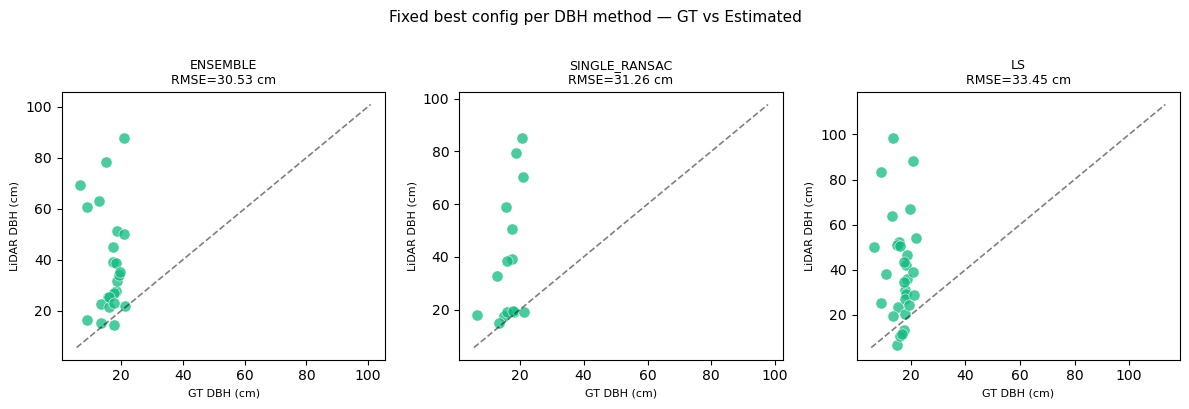

In [13]:
fig, axes = plt.subplots(1, len(df_best_dbh), figsize=(4 * len(df_best_dbh), 4))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]
for ax, (_, conf) in zip(axes_flat, df_best_dbh.iterrows()):
    dm = conf["dbh_method"]
    sub = df_dbh[(df_dbh["dbh_method"] == dm) & (df_dbh["dbh_params"] == conf["dbh_params"])]
    ax.scatter(sub["gt_dbh"], sub["dbh_cm"], c="#10b981", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)
    all_vals = pd.concat([sub["gt_dbh"], sub["dbh_cm"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)
    ax.set_title(f"{dm.upper()}\nRMSE={conf['rmse_cm']:.2f} cm", fontsize=9)
    ax.set_xlabel("GT DBH (cm)", fontsize=8); ax.set_ylabel("LiDAR DBH (cm)", fontsize=8)
for ax in axes_flat[len(df_best_dbh):]: ax.set_visible(False)
plt.suptitle("Fixed best config per DBH method — GT vs Estimated", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


### 7.2 Oracle Analysis — Best DBH Config Chosen Per Individual Tree


╔══ ORACLE vs FIXED CONFIG — DBH RMSE per method ══╗
Method            Oracle RMSE   Fixed RMSE      Gap
----------------------------------------------------
  ensemble            14.4956       30.5305  +16.0349
  single_ransac       29.4929       31.2597   +1.7668
  ls                  30.3108       33.4474   +3.1366


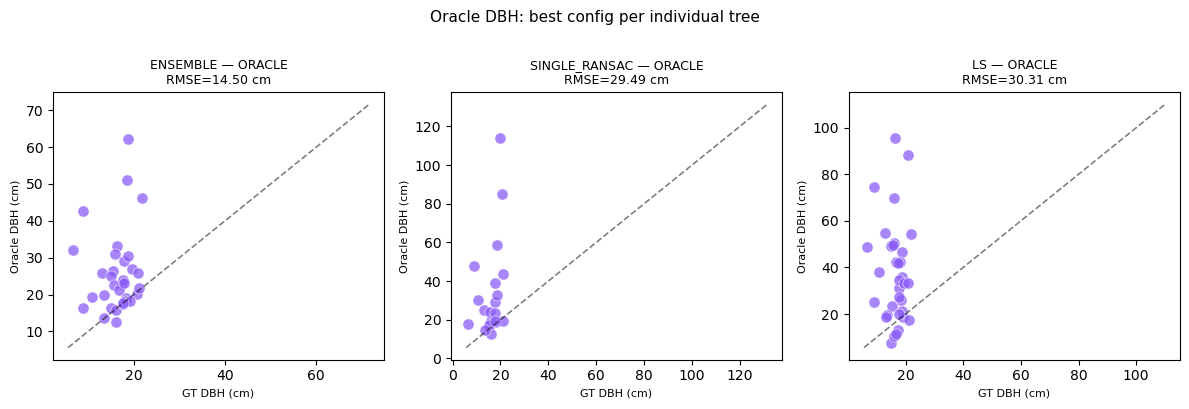

In [14]:
oracle_dbh_rows = []
for dm in df_eval_dbh["dbh_method"].unique():
    dm_data = df_dbh[df_dbh["dbh_method"] == dm]
    for tid, tree_grp in dm_data.groupby("global_tid"):
        gt = tree_grp["gt_dbh"].iloc[0]
        best_idx = (tree_grp["dbh_cm"] - gt).abs().idxmin()
        best_row = tree_grp.loc[best_idx]
        oracle_dbh_rows.append({"global_tid": tid, "dbh_method": dm, "oracle_dbh": best_row["dbh_cm"], "gt_dbh": gt, "abs_err": abs(best_row["dbh_cm"] - gt)})

df_oracle_dbh = pd.DataFrame(oracle_dbh_rows)
print("╔══ ORACLE vs FIXED CONFIG — DBH RMSE per method ══╗")
print(f"{'Method':<16} {'Oracle RMSE':>12} {'Fixed RMSE':>12} {'Gap':>8}")
print("-" * 52)
for dm in df_eval_dbh["dbh_method"].unique():
    fixed_rmse = df_best_dbh[df_best_dbh["dbh_method"] == dm]["rmse_cm"].iloc[0]
    oracle_sub = df_oracle_dbh[df_oracle_dbh["dbh_method"] == dm]
    oracle_rmse = np.sqrt((oracle_sub["abs_err"]**2).mean())
    gap = fixed_rmse - oracle_rmse
    print(f"  {dm:<14} {oracle_rmse:>12.4f}  {fixed_rmse:>12.4f}  {gap:>+8.4f}")

fig, axes = plt.subplots(1, len(df_oracle_dbh["dbh_method"].unique()), figsize=(4 * len(df_oracle_dbh["dbh_method"].unique()), 4))
axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]
for ax, dm in zip(axes_flat, df_oracle_dbh["dbh_method"].unique()):
    sub = df_oracle_dbh[df_oracle_dbh["dbh_method"] == dm]
    ax.scatter(sub["gt_dbh"], sub["oracle_dbh"], c="#8b5cf6", s=65, alpha=0.75, edgecolors="white", linewidths=0.5)
    all_vals = pd.concat([sub["gt_dbh"], sub["oracle_dbh"]])
    mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
    ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)
    o_rmse = np.sqrt(((sub["oracle_dbh"] - sub["gt_dbh"])**2).mean())
    ax.set_title(f"{dm.upper()} — ORACLE\nRMSE={o_rmse:.2f} cm", fontsize=9)
    ax.set_xlabel("GT DBH (cm)", fontsize=8); ax.set_ylabel("Oracle DBH (cm)", fontsize=8)
for ax in axes_flat[len(df_oracle_dbh["dbh_method"].unique()):]: ax.set_visible(False)
plt.suptitle("Oracle DBH: best config per individual tree", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()


## 8. Deep Dive — Specific Parcela Context
Evaluate how one specific plot performs compared to the rest of the dataset.


Deep Dive: Parcela 500 (5 valid trees)

╔══ VOLUME: Target Plot vs All Other Plots ══╗
Method           Target Plot RMSE   Other Plots RMSE
------------------------------------------------------
  voxel                 0.2403 m³          0.1940 m³
  axis_profile          0.3149 m³          0.6000 m³
  cylinder              2.0054 m³          4.8108 m³
  frustum               4.2244 m³          6.0099 m³
  taper                 7.6704 m³         29.0335 m³

╔══ DBH: Target Plot vs All Other Plots ═════╗
Method           Target Plot RMSE   Other Plots RMSE
------------------------------------------------------
  ensemble             23.6602 cm         31.0799 cm
  single_ransac             nan cm         31.2597 cm
  ls                   18.5323 cm         35.1853 cm


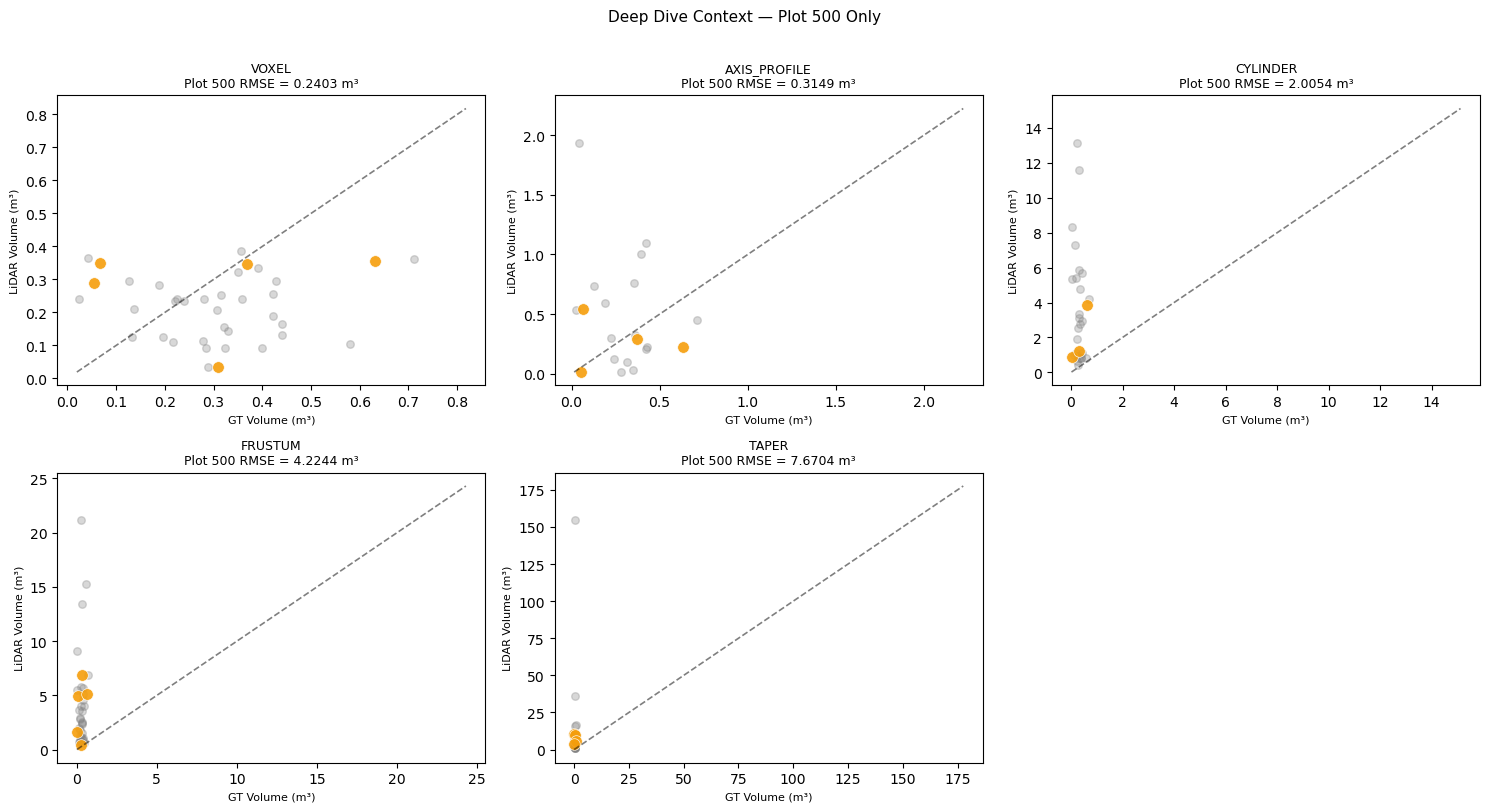

In [15]:
TARGET_PLOT = 500

target_tids = [tid for tid in matched_tids if match_dict[tid]["plot_id"] == TARGET_PLOT]

if not target_tids:
    print(f"No valid matched trees found for Parcela {TARGET_PLOT}.")
else:
    print(f"Deep Dive: Parcela {TARGET_PLOT} ({len(target_tids)} valid trees)\n")
    
    print("╔══ VOLUME: Target Plot vs All Other Plots ══╗")
    print(f"{'Method':<14} {'Target Plot RMSE':>18} {'Other Plots RMSE':>18}")
    print("-" * 54)
    for _, conf in df_best_rmse.iterrows():
        vm = conf["volume_method"]
        sub_all = _get_sub(conf, df_res).dropna(subset=["volume_m3", "gt_volume"])
        sub_target = sub_all[sub_all["global_tid"].isin(target_tids)]
        sub_other = sub_all[~sub_all["global_tid"].isin(target_tids)]
        
        rmse_target = np.sqrt(((sub_target["volume_m3"] - sub_target["gt_volume"])**2).mean()) if len(sub_target) > 0 else float('nan')
        rmse_other = np.sqrt(((sub_other["volume_m3"] - sub_other["gt_volume"])**2).mean()) if len(sub_other) > 0 else float('nan')
        print(f"  {vm:<12} {rmse_target:>15.4f} m³ {rmse_other:>15.4f} m³")

    print("\n╔══ DBH: Target Plot vs All Other Plots ═════╗")
    print(f"{'Method':<14} {'Target Plot RMSE':>18} {'Other Plots RMSE':>18}")
    print("-" * 54)
    for _, conf in df_best_dbh.iterrows():
        dm = conf["dbh_method"]
        sub_all = df_dbh[(df_dbh["dbh_method"] == dm) & (df_dbh["dbh_params"] == conf["dbh_params"])]
        sub_target = sub_all[sub_all["global_tid"].isin(target_tids)]
        sub_other = sub_all[~sub_all["global_tid"].isin(target_tids)]
        
        rmse_target = np.sqrt(((sub_target["dbh_cm"] - sub_target["gt_dbh"])**2).mean()) if len(sub_target) > 0 else float('nan')
        rmse_other = np.sqrt(((sub_other["dbh_cm"] - sub_other["gt_dbh"])**2).mean()) if len(sub_other) > 0 else float('nan')
        print(f"  {dm:<12} {rmse_target:>15.4f} cm {rmse_other:>15.4f} cm")
        
    # Scatter plots
    n_methods = len(df_best_rmse)
    fig, axes = plt.subplots(int(np.ceil(n_methods/3)), 3, figsize=(15, 4 * int(np.ceil(n_methods/3))))
    axes_flat = axes.flatten() if hasattr(axes, "flatten") else [axes]
    
    for ax, (_, conf) in zip(axes_flat, df_best_rmse.iterrows()):
        vm = conf["volume_method"]
        sub_all = _get_sub(conf, df_res).dropna(subset=["volume_m3", "gt_volume"])
        sub_target = sub_all[sub_all["global_tid"].isin(target_tids)]
        sub_other = sub_all[~sub_all["global_tid"].isin(target_tids)]
        
        ax.scatter(sub_other["gt_volume"], sub_other["volume_m3"], c="gray", s=30, alpha=0.3, label="Other Plots")
        if not sub_target.empty:
            ax.scatter(sub_target["gt_volume"], sub_target["volume_m3"], c="#f59e0b", s=70, alpha=0.9, edgecolors="white", linewidths=0.5, label=f"Plot {TARGET_PLOT}")
            
        all_vals = pd.concat([sub_all["gt_volume"], sub_all["volume_m3"]])
        mn, mx = all_vals.min() * 0.85, all_vals.max() * 1.15
        ax.plot([mn, mx], [mn, mx], "k--", lw=1.2, alpha=0.5)
        
        rmse_target = np.sqrt(((sub_target["volume_m3"] - sub_target["gt_volume"])**2).mean()) if len(sub_target) > 0 else float('nan')
        ax.set_title(f"{vm.upper()}\nPlot {TARGET_PLOT} RMSE = {rmse_target:.4f} m³", fontsize=9)
        ax.set_xlabel("GT Volume (m³)", fontsize=8); ax.set_ylabel("LiDAR Volume (m³)", fontsize=8)
        if ax == axes_flat[-1]: ax.legend(fontsize=8)
        
    for ax in axes_flat[n_methods:]: ax.set_visible(False)
    plt.suptitle(f"Deep Dive Context — Plot {TARGET_PLOT} Only", fontsize=11, y=1.01)
    plt.tight_layout()
    plt.show()


## 9. Extrapolation to m³/ha


╔══ VALID TREES EVALUATED PER PLOT ══╗
  Parcela 500 (5 trees): [20, 26, 29, 36, 39]
  Parcela 503 (8 trees): [1, 7, 13, 22, 26, 32, 34, 36]
  Parcela 508 (16 trees): [2, 9, 13, 15, 16, 18, 20, 22, 23, 25, 26, 27, 30, 31, 34, 39]
  Parcela 509 (8 trees): [1, 4, 6, 7, 18, 20, 25, 27]
╚════════════════════════════════════╝



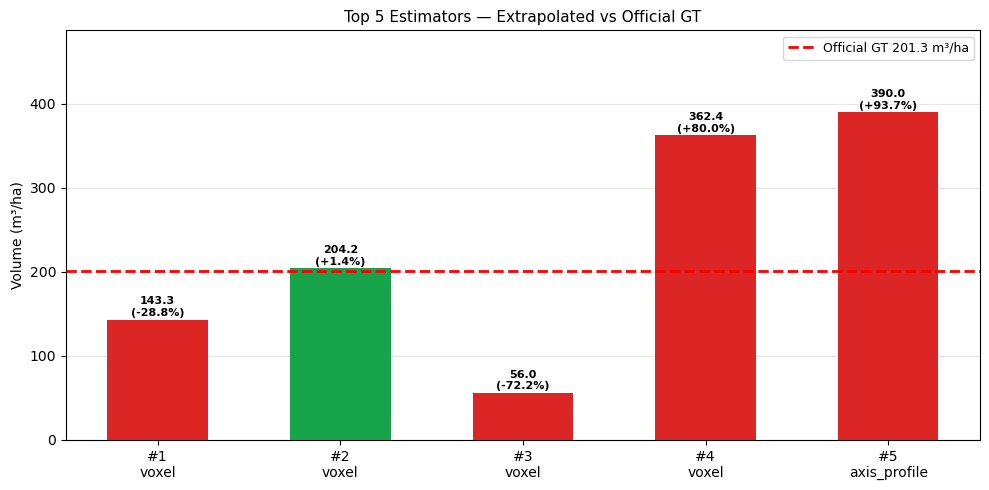

In [16]:
top5 = df_eval.head(5).copy()
gt_ha_by_plot = df_extrap["VTCC (m³/ha)"]
gt_ha_mean = gt_ha_by_plot.mean()

print("╔══ VALID TREES EVALUATED PER PLOT ══╗")
plot_to_trees = {}

# matched_tids contains all the trees that passed QC and have ground truth
for gid in matched_tids:  
    pid = match_dict[gid]["plot_id"]
    tid = gid % 10000  # Extract the original FF3D tree_id

    if pid not in plot_to_trees:
        plot_to_trees[pid] = []
    plot_to_trees[pid].append(tid) 

for pid in sorted(plot_to_trees.keys()):
    tids = sorted(plot_to_trees[pid])
    print(f"  Parcela {pid} ({len(tids)} trees): {tids}")
print("╚════════════════════════════════════╝\n")

extrap_rows = []
for i, (_, conf) in enumerate(top5.iterrows(), 1):
    vm, dm = conf["volume_method"], conf["dbh_method"]
    sub = _get_sub(conf, df_res).dropna(subset=["volume_m3", "gt_volume"])
    per_plot_ha = []
    for pid, pg in sub.groupby("plot_id"):
        n_living  = df_field[(df_field["PAR_CODIGO"] == pid) & df_field["has_gt_volume"]].shape[0]
        n_matched = len(pg)
        if n_matched == 0: continue
        adj_vol  = pg["volume_m3"].sum() * (n_living / n_matched)
        per_plot_ha.append(adj_vol * 25.0)
    mean_ha = np.mean(per_plot_ha)
    err_pct = (mean_ha - gt_ha_mean) / gt_ha_mean * 100
    label = f"#{i}\n{vm}\n({dm[:4]})" if vm == "cylinder" else f"#{i}\n{vm}"
    extrap_rows.append({"label": label, "m3_ha": mean_ha, "err": err_pct})

df_ex = pd.DataFrame(extrap_rows)
fig, ax = plt.subplots(figsize=(max(8, len(df_ex) * 2), 5))
colors = ["#16a34a" if abs(r) < 10 else "#ca8a04" if abs(r) < 20 else "#dc2626" for r in df_ex["err"]]
x_pos = np.arange(len(df_ex))
bars = ax.bar(x_pos, df_ex["m3_ha"], color=colors, width=0.55, zorder=3)
ax.set_xticks(x_pos)
ax.set_xticklabels(df_ex["label"])
ax.axhline(gt_ha_mean, color="red", linestyle="--", linewidth=2, zorder=4, label=f"Official GT {gt_ha_mean:.1f} m³/ha")
for bar, (_, row) in zip(bars, df_ex.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + gt_ha_mean * 0.01, f"{bar.get_height():.1f}\n({row['err']:+.1f}%)", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.set_ylabel("Volume (m³/ha)"); ax.set_ylim(0, max(df_ex["m3_ha"].max(), gt_ha_mean) * 1.25)
ax.set_title("Top 5 Estimators — Extrapolated vs Official GT", fontsize=11)
ax.legend(fontsize=9); ax.grid(axis="y", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()
